Dataset:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Median Target Value: 140.5

Class Distribution:
target
0    221
1    221
Name: count, dtype: int64

Actual Values:
[1 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 1 1
 0 0 1 1 0 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 0 0 0 1 1 1 0
 0 1 1 0 1 1 0 0 0 1 1

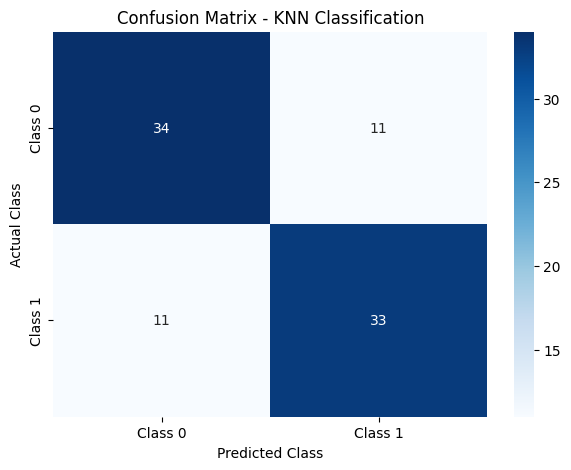


KNN Classification Completed Successfully
Number of Neighbors (K): 5


In [1]:
# Import required libraries
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Diabetes dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Display dataset
print("Dataset:")
print(df.head())

# Input features
X = df.drop("target", axis=1)

# Convert continuous target into two classes
median_target = df["target"].median()
y = (df["target"] >= median_target).astype(int)

print("\nMedian Target Value:", median_target)

print("\nClass Distribution:")
print(y.value_counts().sort_index())

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create KNN model with K = 5
model = KNeighborsClassifier(n_neighbors=5)

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

print("\nAccuracy:",
      round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - KNN Classification")
plt.show()

print("\nKNN Classification Completed Successfully")
print("Number of Neighbors (K):", 5)